# Как получили рамки бабочек и выбрали модель

Пройдите путь одной фотографии от ответа исполнителя до предсказания Gemma, затем проверьте выбор модели на всех 400 снимках. **Run All** читает файлы проекта и пересчитывает метрики на CPU. Отдельная последняя ячейка позволяет заново получить предсказания на NVIDIA GPU.

[Описание данных](data/README.md) · [Галерея итоговой разметки](docs/final_annotations_400.html) · [Инструкция по запуску](docs/reproduce.md)

In [1]:
import base64
import json
import re
import sys
from collections import Counter
from io import BytesIO
from itertools import combinations
from pathlib import Path

from IPython.display import Markdown, display
from PIL import Image

start = Path.cwd().resolve()
for root in (start, *start.parents, start / "shad_razmetka_final_project_26"):
    if (root / "pyproject.toml").is_file() and (root / "butterfly_bench").is_dir():
        break
else:
    raise RuntimeError("Откройте ноутбук в каталоге проекта.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from butterfly_bench.metrics import evaluate, iou

data = root / "data"
results = root / "results/final_400"

def indexed_jsonl(path):
    records = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    indexed = {row["photo_id"]: row for row in records}
    assert len(indexed) == len(records), f"Повторный photo_id в {path.name}"
    return indexed

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, line)) + " |" for line in lines)))

## Какие фотографии вошли в проект

У каждого набора своя роль. На вспомогательных 100 снимках готовили примеры и проверяли настройки моделей. На собственных 400 сравнили модели. Ещё 400 выдал Контест для отдельной сдачи. Категория наблюдения iNaturalist помогает отобрать фотографии, а присутствие взрослой бабочки определяет разметка самого кадра.

In [2]:
reference = indexed_jsonl(data / "reference_100/photos.jsonl")
main = indexed_jsonl(data / "golden_400/photos.jsonl")
contest = indexed_jsonl(data / "contest_400/photos.jsonl")
assert [len(reference), len(main), len(contest)] == [100, 400, 400]
for left, right in combinations((reference, main, contest), 2):
    assert left.keys().isdisjoint(right)
    assert {r["photo_url"] for r in left.values()}.isdisjoint(r["photo_url"] for r in right.values())

sampling = data / "sampling/runs/20261108T001420_435829Z"
audit = indexed_jsonl(sampling / "download_audit.jsonl")
assert audit.keys() == reference.keys() | main.keys()
assert all(row["license_code"].lower() == "cc0" for row in audit.values())
assert len({row["sha256"] for row in audit.values()}) == 500
groups = {"butterfly_observations": "Бабочки", "moth_observations": "Другие чешуекрылые",
          "other_insect_observations": "Другие насекомые", "flower_observations": "Астровые растения"}
reference_counts = Counter(audit[i]["source_stratum"] for i in reference)
main_counts = Counter(audit[i]["source_stratum"] for i in main)
table(["Наблюдения iNaturalist", "Вспомогательный набор", "Набор для оценки"],
      [[name, reference_counts[key], main_counts[key]] for key, name in groups.items()]
      + [["**Всего**", len(reference), len(main)]])
print(f"В аудите загрузки — {len(audit)} снимков CC0. Конкурсных фото — {len(contest)}. Пересечений по ID и URL нет.")

| Наблюдения iNaturalist | Вспомогательный набор | Набор для оценки |
| --- | --- | --- |
| Бабочки | 60 | 240 |
| Другие чешуекрылые | 15 | 60 |
| Другие насекомые | 13 | 50 |
| Астровые растения | 12 | 50 |
| **Всего** | 100 | 400 |

В аудите загрузки — 500 снимков CC0. Конкурсных фото — 400. Пересечений по ID и URL нет.


## Как из двух проходов собрать эталон

В Яндекс Заданиях исполнитель рисовал отдельную рамку вокруг каждой взрослой бабочки. Другой пул видел этот ответ и мог принять или отклонить его. В рабочие пакеты также входили контрольные задания с известным вердиктом. Они служили для проверки ревьюеров.

Ниже из первого пакета извлекаются рабочие ответы. Для снимков, отправленных на переразметку, подставляется ответ из второго пакета. Каждый URL и каждую координату сверяем с опубликованным эталоном.

[Первичная разметка](notebooks/crowd/03a_create_annotation.ipynb) → [Независимая проверка](notebooks/crowd/03b_create_validation.ipynb) → [Повторная разметка](notebooks/crowd/03c_create_reannotation.ipynb) → [Повторная проверка](notebooks/crowd/03d_create_revalidation.ipynb)

In [3]:
def worker_answers(path):
    pages = json.loads(path.read_text())
    answers = {}
    controls = 0
    for page in pages:
        for task in page["tasks"]:
            if "known_solutions" in task:
                controls += 1
                continue
            values = task["input_values"]
            photo_id = values["photo_id"]
            assert photo_id not in answers
            answers[photo_id] = dict(photo_id=photo_id, photo_url=values["image"],
                                     boxes=json.loads(values["boxes_json"]))
    return answers, controls

task_dir = root / "crowd/review/tasks"
first, controls1 = worker_answers(task_dir / "validation_work.json")
revised, controls2 = worker_answers(task_dir / "revalidation.json")
assert len(first) == 400 and len(revised) == 43 and revised.keys() <= first.keys()
gold = first | revised
assert gold == indexed_jsonl(data / "golden_400/annotations.jsonl")
assert {i: row["photo_url"] for i, row in gold.items()} == {i: row["photo_url"] for i, row in main.items()}
truth = {i: row["boxes"] for i, row in gold.items()}
changed = sum(first[i]["boxes"] != revised[i]["boxes"] for i in revised)
print(f"Повторно размечено {len(revised)} снимка, рамки изменились на {changed}. Контрольных заданий: {controls1} + {controls2}.")
print(f"В эталоне {sum(map(len, truth.values()))} рамка на {sum(bool(b) for b in truth.values())} снимках. "
      f"Ещё {sum(not b for b in truth.values())} снимков без рамок.")

Повторно размечено 43 снимка, рамки изменились на 22. Контрольных заданий: 45 + 5.
В эталоне 241 рамка на 220 снимках. Ещё 180 снимков без рамок.


In [4]:
review = indexed_jsonl(data / "golden_400/review.jsonl")
assert review.keys() == gold.keys()
votes = Counter()
for i, row in review.items():
    source = "Повторный ответ" if i in revised else "Первичный ответ"
    assert (row["annotation_source"] == "reannotation_43") == (i in revised)
    verdict = row["review"]
    assert sum(verdict["votes"].values()) == 3
    assert verdict["votes"][verdict["majority"]] >= 2
    votes[source, verdict["majority"]] += 1

table(["Какой ответ включили", "Большинство OK", "Большинство BAD"],
      [[source, votes[source, "OK"], votes[source, "BAD"]] for source in ("Первичный ответ", "Повторный ответ")])
assert (votes["Повторный ответ", "OK"], votes["Повторный ответ", "BAD"]) == (8, 35)

| Какой ответ включили | Большинство OK | Большинство BAD |
| --- | --- | --- |
| Первичный ответ | 357 | 0 |
| Повторный ответ | 8 | 35 |

Все 43 повторных ответа включили по решению заказчика. У 35 из них большинство ревьюеров выбрало **BAD**. У одного из 180 снимков без рамок сохранился статус **UNCERTAIN**. Эти случаи входят в опубликованный эталон и влияют на сравнение моделей. [Происхождение вердиктов](data/golden_400/README.md)

## Одна фотография на трёх этапах

На фото **751308237** бабочку *Aeria olena* пропустили при первом проходе. После переразметки рамку одобрили все три ревьюера. Сопоставим исходный ответ, окончательную разметку и предсказание Gemma на одном и том же встроенном в галерею изображении.

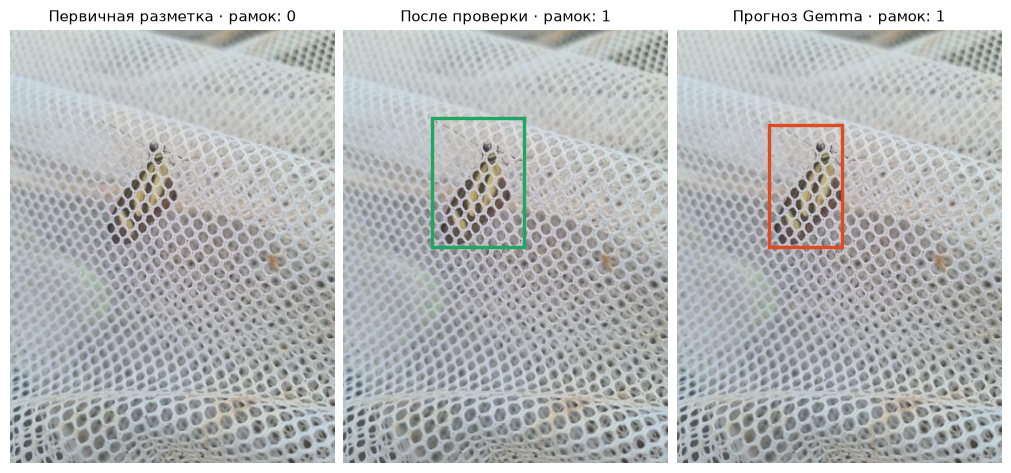

Повторная проверка: {'OK': 3}. IoU рамки Gemma с эталоном: 0.751.


In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

photo_id = 751308237
gemma = indexed_jsonl(results / "gemma/predictions.jsonl")
gallery = (root / "docs/final_annotations_400.html").read_text()
article = re.search(rf'<article\b[^>]*data-id="{photo_id}"[^>]*>(.*?)</article>', gallery, re.S)
assert article is not None, f"В галерее нет фото {photo_id}"
jpeg = re.search(r'<img\b[^>]*src="data:image/jpeg;base64,([^"]+)"', article[1])
assert jpeg is not None
with Image.open(BytesIO(base64.b64decode(jpeg[1]))) as source:
    picture = source.convert("RGB")

panels = [("Первичная разметка", first[photo_id]["boxes"], "#777777"),
          ("После проверки", truth[photo_id], "#1fa762"),
          ("Прогноз Gemma", gemma[photo_id]["boxes"], "#df4b21")]
fig, axes = plt.subplots(1, 3, figsize=(10, 4.8), layout="constrained")
for ax, (title, boxes, color) in zip(axes, panels):
    ax.imshow(picture)
    for box in boxes:
        ax.add_patch(Rectangle((box["left"] * picture.width, box["top"] * picture.height),
                               box["width"] * picture.width, box["height"] * picture.height,
                               linewidth=2.4, edgecolor=color, fill=False))
    ax.set_title(f"{title} · рамок: {len(boxes)}", fontsize=11)
    ax.axis("off")
plt.show()
example_iou = iou(truth[photo_id][0], gemma[photo_id]["boxes"][0])
print(f"Повторная проверка: {review[photo_id]['review']['votes']}. IoU рамки Gemma с эталоном: {example_iou:.3f}.")

## Как сравнивались модели

Одна предсказанная рамка может совпасть только с одной эталонной. Метрика **object F1** учитывает пропуски и лишние рамки. Порог IoU 0,50 используется для выбора победителя, а IoU 0,75 строже оценивает точность границ. Пересчитываем показатели штатной функцией проекта на всех 400 снимках и сверяем их с архивом запуска.

In [6]:
models = {"grounding_dino": "Grounding DINO tiny", "owlv2": "OWLv2 base",
          "qwen": "Qwen3-VL-2B", "gemma": "Gemma 4 12B QAT"}
scores = {}
for key in models:
    predictions = gemma if key == "gemma" else indexed_jsonl(results / key / "predictions.jsonl")
    measured = evaluate(predictions, truth)
    saved = json.loads((results / key / "metrics.json").read_text())
    assert all(value == saved[name] for name, value in measured.items()), key
    scores[key] = {**measured, "seconds": saved["mean_image_seconds"]}

ranking = sorted(models, key=lambda key: (-scores[key]["f1"], scores[key]["seconds"]))
rows = []
for key in ranking:
    m = scores[key]
    rows.append([models[key], f"{m['f1']:.4f}", f"{m['iou_0.75/f1']:.4f}", f"{m['precision']:.3f}",
                 f"{m['recall']:.3f}", m["fp"], m["fn"], m["negative_fp"], m["processing_errors"],
                 f"{m['seconds']:.2f}"])
table(["Модель", "F1@0,50", "F1@0,75", "Precision", "Recall", "FP", "FN",
       "FP на пустых", "Сбои", "с/фото¹"], rows)
print(f"По F1@0,50 лидирует {models[ranking[0]]}.")
print("¹ Среднее время обработки фотографии по журналу исходного GPU-запуска.")
for record in gemma.values():
    if record["error"] is not None:
        print(f"Сбой Gemma на фото {record['photo_id']}: {record['error']}.")

| Модель | F1@0,50 | F1@0,75 | Precision | Recall | FP | FN | FP на пустых | Сбои | с/фото¹ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Gemma 4 12B QAT | 0.8536 | 0.4907 | 0.848 | 0.859 | 37 | 34 | 10 | 1 | 1.67 |
| Grounding DINO tiny | 0.5793 | 0.5013 | 0.416 | 0.954 | 323 | 11 | 277 | 0 | 0.17 |
| OWLv2 base | 0.5711 | 0.3950 | 0.410 | 0.942 | 327 | 14 | 112 | 0 | 0.19 |
| Qwen3-VL-2B | 0.3753 | 0.0442 | 0.401 | 0.353 | 127 | 156 | 26 | 0 | 1.08 |

По F1@0,50 лидирует Gemma 4 12B QAT.
¹ Среднее время обработки фотографии по журналу исходного GPU-запуска.
Сбой Gemma на фото 751710021: ValidationError: box 0: invalid origin or nonpositive size.


Gemma выиграла по основной метрике. Grounding DINO чаще находит бабочек, но также чаще рисует лишние рамки. У него немного выше F1 при IoU 0,75. Сохранённый технический отказ Gemma учитывается при оценке, а эталонные объекты проблемного изображения засчитываются как пропуски.

## Повторить запуск победителя на GPU

Выполняйте этот раздел на NVIDIA GPU после установки среды инференса и сборки CUDA-версии llama.cpp. При `RUN_INFERENCE = True` загрузятся веса и данные закреплённых ревизий. Укажите **1** для фотографии из примера или **400** для полного сравнения. В исторической ревизии Hugging Face собственные 400 размеченных снимков назывались `test`. Последующее переименование в `validation` описано в отчёте. [Настройка среды](docs/reproduce.md) · [Соответствие выборок](results/experiments/split_migration_2026-11-16/README.md)

In [7]:
RUN_INFERENCE = False
N_IMAGES = 1  # 1 или 400

if RUN_INFERENCE:
    import os
    from datetime import datetime, timezone

    os.environ.setdefault("HF_HOME", str(root.parent / "downloads/final-project/huggingface"))

    from omegaconf import OmegaConf
    from butterfly_bench.pipeline import run

    if N_IMAGES not in (1, 400):
        raise ValueError("Выберите один снимок или все 400.")
    cfg = OmegaConf.load(results / "frozen/gemma.yaml")
    cfg.data.photo_ids = [photo_id] if N_IMAGES == 1 else None
    cfg.model.server_binary = str(root / cfg.model.server_binary)
    cfg.comet.mode = "disabled"
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    cfg.output_dir = str(root / "outputs/pipeline" / f"gemma_{N_IMAGES}_{stamp}")
    run_result = run(cfg)
    print(run_result["status"], run_result["output_dir"])
    print(f"Обработано: {run_result['metrics']['images']}. F1@0,50: {run_result['metrics']['f1']:.4f}.")
else:
    print("Офлайн-проверка завершена. Для нового прогона Gemma включите RUN_INFERENCE.")

Офлайн-проверка завершена. Для нового прогона Gemma включите RUN_INFERENCE.
